In [1]:
#| include: false
import math
import random

import matplotlib.pyplot as plt
import numpy as np

from lab import ACCENT, MUTED, setup

setup()

A neuron in a neural network is loosely inspired by a human neuron. It takes some inputs in the form of data and multiplies each one by a weight, a value that says how strongly that input counts, a bit like the strength of a synapse between two real neurons. After a forward pass, in which the neural network tries to label or generate stuff, backpropagation calculates the impact each weight had on the loss (how wrong it was), and then we can tweak those weights to make the loss smaller. If everything goes well, after many cycles, the predictions or generations will be good enough (depending on how we define that).

To do this in Python, we usually use PyTorch, which has built-in tools for this purpose. Here's a tiny autograd (that means automatic gradient) engine so we can understand what PyTorch does under the hood at a high level. This is mostly based on Andrej Karpathy's [micrograd](https://github.com/karpathy/micrograd). Check out [his YouTube video](https://www.youtube.com/watch?v=VMj-3S1tku0) explaining how it works.

If a neuron has one data input and one weight, we multiply the value of the input by the value of the weight and add a bias:

$$z = x_1 w_1 + b$$

This $z$ is called the pre-activation. To get the neuron's activation, we run $z$ through a squashing function, like tanh or sigmoid. Sigmoid is

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Here's what sigmoid does for different inputs:

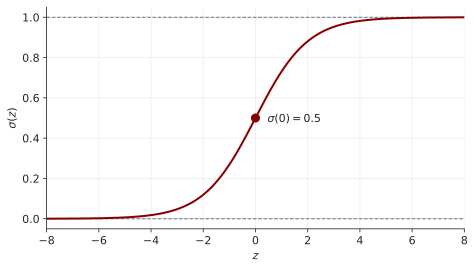

In [2]:
#| echo: false
#| alt: The sigmoid curve from z = -8 to 8. It stays near 0 for negative inputs, passes through 0.5 at z = 0, and levels off near 1 for positive inputs.
#| caption: Sigmoid squashes any input into the range 0 to 1.
#| name: sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 400)

fig, ax = plt.subplots()
for y in (0, 1):
    ax.axhline(y, color=MUTED, linestyle="--", linewidth=1)
(line,) = ax.plot(z, sigmoid(z))
ax.plot(0, 0.5, "o", markersize=8, color=line.get_color())
ax.annotate(r"$\sigma(0) = 0.5$", (0, 0.5), xytext=(12, -4), textcoords="offset points")
ax.set_xlabel("$z$")
ax.set_ylabel(r"$\sigma(z)$")
ax.set_xlim(-8, 8)
ax.set_ylim(-0.05, 1.05)
plt.show()

## The dataset

So for this experiment, we're going to train a tiny neural net to make good predictions for this dataset:

In [3]:
rng = np.random.default_rng(1)

n_students = 80
study = rng.uniform(0, 6, n_students)  # hours studied
sleep = rng.uniform(4, 10, n_students)  # hours slept the night before
passed = (study > 3) & (sleep > 7)

xs = [[float(st) / 10, float(sl) / 10] for st, sl in zip(study, sleep)]  # hours / 10
ys = [1.0 if p else 0.0 for p in passed]

print(f"{len(xs)} students, {sum(ys):.0f} passed")

80 students, 21 passed


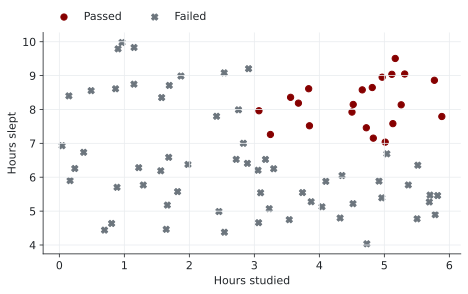

In [4]:
#| echo: false
#| alt: A scatter plot of 80 students, hours studied from 0 to 6 on the x axis and hours slept from 4 to 10 on the y axis. The students who passed fill the top-right corner, where study is above 3 hours and sleep is above 7 hours. Everyone else failed.
#| caption: Students pass only with enough study and enough sleep.
#| name: dataset
fig, ax = plt.subplots()
ax.scatter(study[passed], sleep[passed], s=40, color=ACCENT, label="Passed")
ax.scatter(study[~passed], sleep[~passed], s=40, color=MUTED, marker="X", label="Failed")
ax.set_xlabel("Hours studied")
ax.set_ylabel("Hours slept")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
plt.show()

Each student has two inputs, $x_1$ for hours studied and $x_2$ for hours slept, and one label, $y$, which is 1 if they passed and 0 if they didn't. We divide the hours by 10 so the inputs are between 0 and 1 (more on why when we train the network). The data is made up: a student passes if they studied more than 3 hours and slept more than 7. The network doesn't know that rule, so the whole point of training is for it to figure it out from the examples.

We use 0 and 1 for the labels because the network's output goes through a sigmoid, so it's always somewhere between 0 and 1. We can read it as how sure the network is that a student passed (0.9 means "pretty sure they passed", 0.1 means "pretty sure they didn't").

Notice that the students who passed are all in the top-right corner. A single neuron can only split the plot with a straight line (it adds up its weighted inputs and squashes the result), and one straight line can't cut out a corner. So we'll need a few neurons working together, which is what a network is.

## Derivatives and gradients

Before the code, a quick review of what a derivative is, since the whole thing is built on it. A derivative tells us how much a function's output changes when we change its input a tiny bit. Take two points on a curve, one at $x$ and one a little further at $x + h$. The slope of the line between them is how much the curve went up divided by how far we moved:

$$\frac{f(x + h) - f(x)}{h}$$

Now if we slide the second point closer and closer to the first one, until the distance $h$ is basically zero, that line ends up just touching the curve at $x$ (that's called the tangent). Its slope is the derivative:

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

This only works if the curve is smooth there, with no sharp corners or jumps (that's what differentiable means). Sigmoid is smooth everywhere. Its slope is steepest in the middle, where $\sigma'(0) = 0.25$, and almost flat at the ends, where the curve levels off.

For a more intuitive feel for derivatives (and calculus in general), check out 3Blue1Brown's [Essence of calculus](https://www.3blue1brown.com/lessons/essence-of-calculus) videos. They're really good at showing what's going on visually.

The loss doesn't depend on just one number, though. It depends on every weight and bias in the network. So we take one derivative for each of them: we nudge one parameter, keep all the others the same, and see how the loss changes. That's called a partial derivative, and we write it with a $\partial$. For example, $\frac{\partial L}{\partial w_1}$ is how much the loss $L$ changes when we nudge $w_1$.

The gradient is just all of those partial derivatives put together, one for each parameter we can tweak:

$$\nabla L = \left( \frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}, \ldots, \frac{\partial L}{\partial b} \right)$$

So each number in the gradient tells us how one weight or bias affects the loss. The sign tells us which way to move it to make the loss smaller, and the size tells us how much it matters.

To work those out, we use local derivatives. A weight doesn't affect the loss directly. It goes through a few small steps first (multiply, add, squash, and so on), and each step has its own simple derivative. The chain rule says we can multiply those together to get from the weight all the way to the loss. For the one-input neuron from the top, where $a = \sigma(z)$:

$$\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} \cdot \frac{\partial z}{\partial w_1}$$

Working out all those local derivatives and chaining them together is what backpropagation does, and it's why `Scalar` keeps track of where each number came from. For the same ideas without the code, there are longer guides on [how a neural network works](https://berges.ai/guides/how-a-neural-network-works) and [backpropagation](https://berges.ai/guides/backpropagation).

## The Scalar class

The autograd engine is just one class, `Scalar`. It holds a single number, and every time we add or multiply two of them, the result remembers which ones it came from, so later we can go back through them and work out the gradients:

In [5]:
class Scalar:
    def __init__(self, data, children=()):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(children)

    def __repr__(self):
        return f"Scalar(data={self.data:.4f}, grad={self.grad:.4f})"

    def __add__(self, other):
        other = other if isinstance(other, Scalar) else Scalar(other)
        out = Scalar(self.data + other.data, (self, other))

        def _backward():
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Scalar) else Scalar(other)
        out = Scalar(self.data * other.data, (self, other))

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def sigmoid(self):
        s = 1 / (1 + math.exp(-self.data))
        out = Scalar(s, (self,))

        def _backward():
            self.grad += s * (1 - s) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        order = []
        visited = set()

        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build(child)
                order.append(v)

        build(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()

Notice the following:

- We're using scalars (plain numbers) instead of matrices. PyTorch stores numbers in tensors (arrays with any number of dimensions: a single number, a list, a matrix, or more) and does the math on whole matrices at once, which is way faster. Going one number at a time is slower, but it lets us follow every step of backpropagation.
- `data` is the number itself, and `grad` is how much the final output changes when this number changes, $\frac{\partial \text{out}}{\partial \text{value}}$. It starts at 0 because we haven't backpropagated anything yet. When the output is the loss, the `grad`s of all the weights and biases together are the gradient.
- `_prev` keeps the numbers this one was made from, so all the `Scalar`s together form a graph we can walk backwards.
- Each operation also stores a `_backward` function, and there's a `backward()` method. Those are what actually work out the gradients, and we'll come back to them when we train the network.

## The network

So let's create basic classes for neuron, layer of neurons, and network:

In [6]:
class Neuron:
    def __init__(self, n_inputs):
        self.w = [Scalar(random.uniform(-1, 1)) for _ in range(n_inputs)]
        self.b = Scalar(random.uniform(-1, 1))

    def __call__(self, x):
        z = self.b
        for wi, xi in zip(self.w, x):
            z = z + wi * xi
        return z.sigmoid()

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.neurons = [Neuron(n_inputs) for _ in range(n_neurons)]

    def __call__(self, x):
        return [neuron(x) for neuron in self.neurons]

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class Network:
    def __init__(self, n_inputs, layer_sizes):
        sizes = [n_inputs] + layer_sizes
        self.layers = [Layer(sizes[i], sizes[i + 1]) for i in range(len(layer_sizes))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x[0] if len(x) == 1 else x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [7]:
random.seed(42)

net = Network(2, [4, 1])
out = net(xs[0])

print("first student:", [round(v, 2) for v in xs[0]], "label:", ys[0])
print("prediction:", out)
print("parameters:", len(net.parameters()))

first student: [0.31, 0.8] label: 1.0
prediction: Scalar(data=0.2616, grad=0.0000)
parameters: 17


Notice the following:

- A `Neuron` does the same thing as the formula at the top, just with more inputs: $\sigma\left(\sum_i x_i w_i + b\right)$. Its weights start out random, so the neurons in a layer don't all start the same and end up learning the same thing. The seed is only there so this page shows the same numbers every time it runs.
- A `Layer` is just a list of neurons that all get the same inputs. Its outputs become the inputs of the next layer.
- `Network(2, [4, 1])` takes our 2 inputs (hours studied and hours slept), runs them through a hidden layer of 4 neurons, and then into 1 output neuron that gives us the prediction. That's $4 \cdot (2 + 1) + 1 \cdot (4 + 1) = 17$ parameters, since each neuron has one weight per input plus a bias.
- The inputs are plain floats, and that's fine: `wi * xi` still works because `__mul__` turns `xi` into a `Scalar`.
- `__call__` lets us use a neuron, layer or network like a function, `net(x)`.
- `parameters()` collects everything training is allowed to tweak. Since the weights are still random, the prediction is just a guess for now.

## Training

Now we can put it all together and train the network. Each step of the loop does three things:

1. Forward pass: run every student through the network and measure how wrong the predictions were (the loss).
2. Backward pass: zero the old gradients, then call `backward()` on the loss to work out the new ones.
3. Update: nudge every weight and bias a little in the opposite direction of its gradient, so the loss goes down.

For the loss we use the mean squared error. For each student, we take the difference between the prediction $\hat{y}$ and the label $y$, square it (so being wrong in either direction counts, and being very wrong counts a lot more), and then average over all the students:

$$L = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2$$

The update for each parameter $p$ is

$$p \leftarrow p - \eta \, \frac{\partial L}{\partial p}$$

where $\eta$ (eta) is the learning rate, which says how big a step we take each time.

In [8]:
learning_rate = 4.0
steps = 3000


def train(net, log=True):
    losses = []
    for step in range(steps):
        # forward pass
        loss = Scalar(0.0)
        for x, y in zip(xs, ys):
            diff = net(x) + (-y)
            loss = loss + diff * diff
        loss = loss * (1 / len(xs))
        losses.append(loss.data)

        # backward pass
        for p in net.parameters():
            p.grad = 0.0
        loss.backward()

        # update
        for p in net.parameters():
            p.data -= learning_rate * p.grad

        if log and (step % 300 == 0 or step == steps - 1):
            print(f"step {step:4d}  loss {loss.data:.4f}")
    return losses


random.seed(42)
net = Network(2, [4, 1])
losses = train(net)

step    0  loss 0.1922


step  300  loss 0.0670


step  600  loss 0.0524


step  900  loss 0.0424


step 1200  loss 0.0333


step 1500  loss 0.0255


step 1800  loss 0.0198


step 2100  loss 0.0159


step 2400  loss 0.0132


step 2700  loss 0.0112


step 2999  loss 0.0098


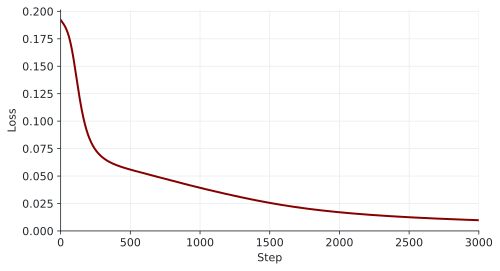

In [9]:
#| echo: false
#| alt: The training loss over 3000 steps. It starts around 0.19, drops quickly in the first 300 steps, and then keeps going down slowly to about 0.01.
#| caption: The loss goes down as the network trains.
#| name: loss
fig, ax = plt.subplots()
ax.plot(losses)
ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.set_xlim(0, steps)
ax.set_ylim(bottom=0)
plt.show()

To check how well it did, we count a prediction above 0.5 as "passed" (the network is more sure they passed than not) and compare it with the label:

In [10]:
def correct(net):
    return sum((net(x).data > 0.5) == (y == 1.0) for x, y in zip(xs, ys))


print(f"accuracy: {correct(net)}/{len(ys)} ({correct(net) / len(ys):.0%})")

accuracy: 80/80 (100%)


And here's what the network learned. The shaded area is where it predicts a student passes, and the dashed line is the rule we used to make up the data:

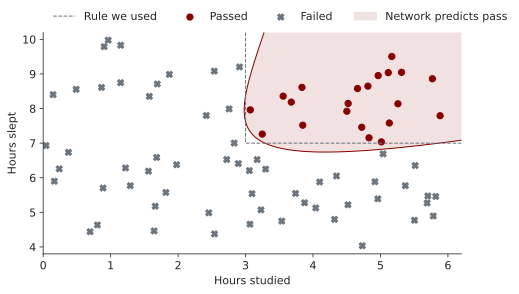

In [11]:
#| echo: false
#| alt: The student scatter plot again, with the area where the trained network predicts a pass shaded in red. The shaded area covers the top-right corner and follows the dashed lines at 3 hours studied and 7 hours slept that mark the real rule, with a rounded corner. Every student who passed is inside it and every student who failed is outside.
#| caption: The trained network finds a rounded version of the corner on its own.
#| name: boundary
from matplotlib.patches import Patch

grid_study = np.linspace(0, 6.2, 80)
grid_sleep = np.linspace(3.8, 10.2, 80)
grid = np.array([[net([st / 10, sl / 10]).data for st in grid_study] for sl in grid_sleep])

fig, ax = plt.subplots()
ax.contourf(grid_study, grid_sleep, grid, levels=[0.5, 1], colors=[ACCENT], alpha=0.12)
ax.contour(grid_study, grid_sleep, grid, levels=[0.5], colors=[ACCENT], linewidths=1)
ax.plot([3, 3, 6.2], [10.2, 7, 7], color=MUTED, linestyle="--", linewidth=1, label="Rule we used")
ax.scatter(study[passed], sleep[passed], s=40, color=ACCENT, label="Passed")
ax.scatter(study[~passed], sleep[~passed], s=40, color=MUTED, marker="X", label="Failed")
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(color=ACCENT, alpha=0.12))
labels.append("Network predicts pass")
ax.legend(handles, labels, loc="lower left", bbox_to_anchor=(0, 1), ncol=4)
ax.set_xlabel("Hours studied")
ax.set_ylabel("Hours slept")
ax.set_xlim(0, 6.2)
ax.set_ylim(3.8, 10.2)
ax.grid(False)
plt.show()

For comparison, here's the same training with a single neuron and no hidden layer:

In [12]:
random.seed(42)
single = Network(2, [1])
train(single, log=False)

print(f"accuracy: {correct(single)}/{len(ys)} ({correct(single) / len(ys):.0%})")

accuracy: 75/80 (94%)


Notice the following:

- We divided the hours by 10 back when we made the dataset, so the inputs are between 0 and 1. With raw hours, $z$ can get big, and then the sigmoid is at the flat ends of the curve, where the derivative is almost 0. Almost-zero gradients mean the weights barely move, so the network learns really slowly.
- `+ (-y)` is just subtraction. `Scalar` only knows how to add and multiply, and that's enough.
- `backward()` starts at the loss and goes backwards through the graph, so every `Scalar` gets its gradient after everything that came from it has been handled (that order is called a topological sort). It sets the loss's own gradient to 1, since $\frac{\partial L}{\partial L} = 1$, and then calls each `_backward` along the way.
- Each `_backward` applies one local derivative. For $z = a + b$, $\frac{\partial z}{\partial a} = 1$, so the gradient just passes through. For $z = a \cdot b$, $\frac{\partial z}{\partial a} = b$, so each side gets the other side's value times the gradient coming in from above. For sigmoid, the derivative can be written with sigmoid itself, so it reuses `s` instead of computing the exponential again:

$$\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$$

- The gradients use `+=` instead of `=` because one number can feed into more than one operation (every weight is used once per student), and its gradient is the sum of what comes back from each one. That's also why we zero the gradients before every backward pass. Otherwise each step would add its gradients on top of the last step's, and the updates would keep growing and stop matching where the weights are now. PyTorch does the same thing, which is why training loops there call `optimizer.zero_grad()`.
- The minus sign in the update is because the gradient points in the direction where the loss goes up, and we want it to go down.
- A learning rate of 4 is a lot bigger than what you usually see in PyTorch examples (often something like 0.01). Here the gradients are small (the sigmoid's slope is never more than 0.25, and the loss is an average), so we need bigger steps. Higher rates make the loss jump around more, but here it still gets there. By 64, the steps are so big that the network gets stuck predicting that everyone fails. Going lower works too, it just takes more steps to find the corner.
- Every step builds a brand new graph from scratch, with thousands of `Scalar`s, which is why 3000 steps take a while (around 15 seconds here) even with only 80 students. That's the slowness from going one number at a time.
- The single neuron gets about 94%, because the best it can do is a straight line across the corner. The hidden layer is what lets the network bend the line.
- The 100% is for this seed. With seeds 0 to 9, it lands between 94% and 100% after 3000 steps, so try changing the seed and see what you get.
- The accuracy is on the same students we trained on, so it says the network fit this data, not that it would do well on new students. In the real world, we'd keep some students aside (a test set) and check on those.